In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost shap openpyxl xlrd joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE

import shap
import joblib

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_excel("dataset.xls", header=1)

In [4]:
print("Shape:", df.shape)

Shape: (30000, 25)


In [5]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [6]:
print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [9]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

missing_values[missing_values > 0]

Total missing values: 0


Series([], dtype: int64)

In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [11]:
target_counts = df["default payment next month"].value_counts()

print(target_counts)

print("\nTarget Percentage:")
print(df["default payment next month"].value_counts(normalize=True) * 100)

default payment next month
0    23364
1     6636
Name: count, dtype: int64

Target Percentage:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


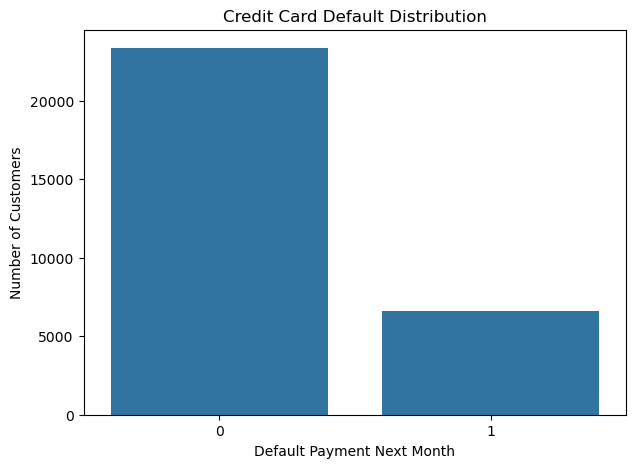

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x="default payment next month",
    data=df
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Payment Next Month")
plt.ylabel("Number of Customers")

plt.show()

In [13]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (30000, 25)


In [14]:
df = df.drop(columns=["ID"])

print("ID column removed.")
print("New shape:", df.shape)

ID column removed.
New shape: (30000, 24)


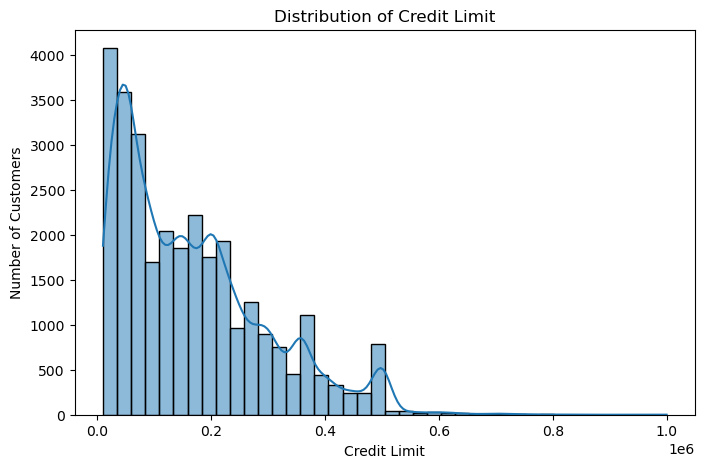

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40,
    kde=True
)

plt.title("Distribution of Credit Limit")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")

plt.show()

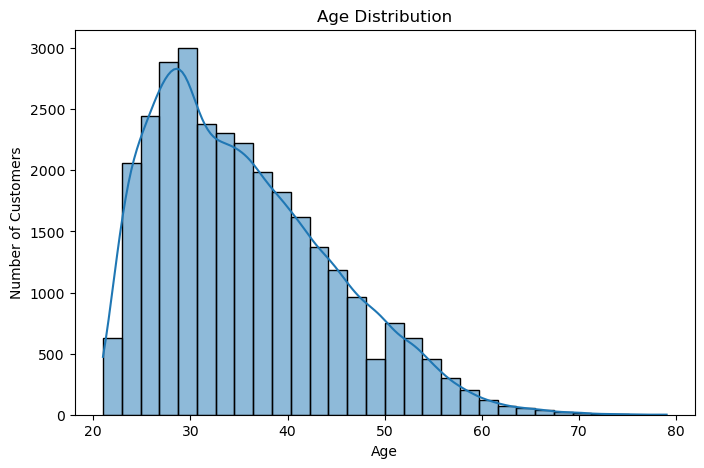

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="AGE",
    bins=30,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

## 5. Feature Engineering
Create five financial-behaviour features from the six monthly bill/payment columns.

In [17]:
bill_columns = [
    "BILL_AMT1","BILL_AMT2","BILL_AMT3",
    "BILL_AMT4","BILL_AMT5","BILL_AMT6"
]

payment_columns = [
    "PAY_AMT1","PAY_AMT2","PAY_AMT3",
    "PAY_AMT4","PAY_AMT5","PAY_AMT6"
]

df["Total_Bill_Amount"] = df[bill_columns].sum(axis=1)
df["Total_Payment_Amount"] = df[payment_columns].sum(axis=1)
df["Average_Bill_Amount"] = df[bill_columns].mean(axis=1)
df["Average_Payment_Amount"] = df[payment_columns].mean(axis=1)

df["Payment_Ratio"] = (
    df["Total_Payment_Amount"] /
    (df["Total_Bill_Amount"].abs() + 1)
)

engineered_features = [
    "Total_Bill_Amount",
    "Total_Payment_Amount",
    "Average_Bill_Amount",
    "Average_Payment_Amount",
    "Payment_Ratio"
]

print("Feature engineering completed!")
display(df[engineered_features].describe().T)

Feature engineering completed!


,count,mean,std,min,25%,50%,75%,max
Total_Bill_Amount,30000.0,269861.671200,379564.331162,-336259.000000,28688.000000,126311.000000,342626.500000,5.263883e+06
Total_Payment_Amount,30000.0,31651.392567,60827.677939,0.000000,6679.750000,14383.000000,33503.500000,3.764066e+06
Average_Bill_Amount,30000.0,44976.945200,63260.721860,-56043.166667,4781.333333,21051.833333,57104.416667,8.773138e+05
Average_Payment_Amount,30000.0,5275.232094,10137.946323,0.000000,1113.291667,2397.166667,5583.916667,6.273443e+05
Payment_Ratio,30000.0,21.216778,1255.766173,0.000000,0.041302,0.087865,0.608768,1.620000e+05


## 6. Separate Features and Target

In [18]:
X = df.drop(columns=["default payment next month"])
y = df["default payment next month"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (30000, 28)
Target shape: (30000,)


## 7. Train/Test Split — Test Set Remains Unseen

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (24000, 28)
Testing : (6000, 28)


## 8. Preprocessing

In [20]:
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(
    X_train_processed, columns=feature_names, index=X_train.index
)
X_test_processed_df = pd.DataFrame(
    X_test_processed, columns=feature_names, index=X_test.index
)

print("Processed training:", X_train_processed.shape)
print("Processed testing :", X_test_processed.shape)
print("Processed features:", len(feature_names))

Processed training: (24000, 38)
Processed testing : (6000, 38)
Processed features: 38


## 9. SMOTE Experiment — Training Data Only
SMOTE is retained for comparison. It is not automatically selected as the final accuracy model because resampling can reduce overall accuracy.

In [21]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed, y_train
)

print("Before SMOTE:", X_train_processed.shape)
print("After SMOTE :", X_train_smote.shape)
print("\nBefore SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE: (24000, 38)
After SMOTE : (37382, 38)

Before SMOTE:
default payment next month
0    18691
1     5309
Name: count, dtype: int64

After SMOTE:
default payment next month
0    18691
1    18691
Name: count, dtype: int64


## 10. Logistic Regression — Accuracy-Oriented Baseline

In [22]:
logistic_model = LogisticRegression(
    max_iter=3000,
    C=0.5,
    solver="lbfgs",
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

lr_prob = logistic_model.predict_proba(X_test_processed)[:, 1]
lr_pred = (lr_prob >= 0.50).astype(int)

print("Logistic Regression trained.")

Logistic Regression trained.


## 10. Random Forest Model
Random Forest trains multiple decision trees and combines their predictions. It uses the same processed training data as Logistic Regression and XGBoost for a fair comparison.


In [23]:
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train on the original training data, matching the non-SMOTE baseline models.
random_forest_model.fit(X_train_processed, y_train)

rf_prob = random_forest_model.predict_proba(X_test_processed)[:, 1]
rf_pred = (rf_prob >= 0.50).astype(int)

print("Random Forest trained successfully.")
print("Random Forest test predictions generated.")

Random Forest trained successfully.
Random Forest test predictions generated.


## 11. XGBoost Hyperparameter Tuning
Accuracy is used as the cross-validation scoring metric because the project has an explicit accuracy requirement. The test set is not used for tuning.

In [24]:
xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [3, 4],
    "learning_rate": [0.03, 0.05],
    "subsample": [0.85, 1.0],
    "colsample_bytree": [0.85, 1.0]
}

xgb_search = GridSearchCV(
    xgb_base,
    param_grid=param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train_processed, y_train)

print("Best parameters:")
print(xgb_search.best_params_)
print("Best CV accuracy:",
      round(xgb_search.best_score_ * 100, 2), "%")

xgb_model = xgb_search.best_estimator_

Fitting 3 folds for each of 32 candidates, totalling 96 fits
Best parameters:
{'colsample_bytree': 0.85, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.85}
Best CV accuracy: 82.17 %


## 12. Validation-Based Threshold Optimization
The classification threshold is selected using a validation split from the training data, not the test set. This avoids test-set leakage.

In [25]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_processed, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

threshold_model = XGBClassifier(
    **xgb_search.best_params_,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

threshold_model.fit(X_fit, y_fit)
val_prob = threshold_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.81, 0.01):
    val_pred = (val_prob >= threshold).astype(int)
    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, val_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[threshold_df["Accuracy"].idxmax()]
best_threshold = float(best_row["Threshold"])

print("Best validation threshold:", best_threshold)
print("Validation accuracy:",
      round(float(best_row["Accuracy"]) * 100, 2), "%")

Best validation threshold: 0.51
Validation accuracy: 82.02 %


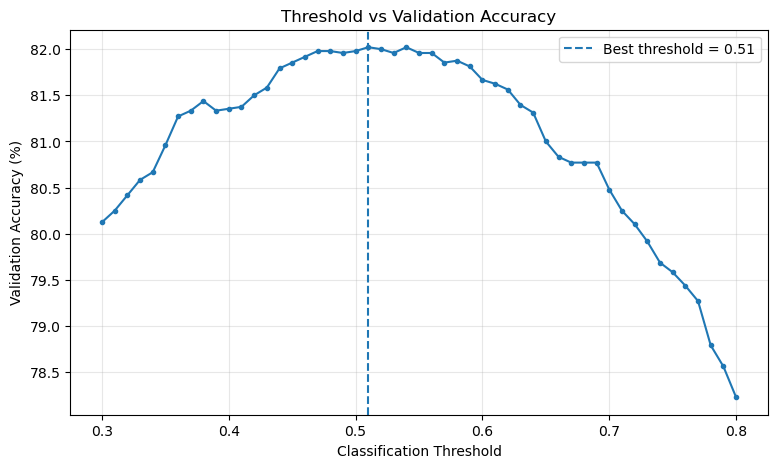

In [26]:
plt.figure(figsize=(9, 5))
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Accuracy"] * 100,
    marker="o",
    markersize=3
)
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)
plt.xlabel("Classification Threshold")
plt.ylabel("Validation Accuracy (%)")
plt.title("Threshold vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 13. Final Test Predictions

In [27]:
xgb_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

# Final XGBoost prediction uses the threshold selected on validation data.
xgb_pred = (xgb_prob >= best_threshold).astype(int)

print("Final XGBoost test predictions generated.")

Final XGBoost test predictions generated.


## 14. Model Evaluation

In [28]:
def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results_df = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, lr_pred, lr_prob),
    evaluate_model("Random Forest", y_test, rf_pred, rf_prob),
    evaluate_model("XGBoost", y_test, xgb_pred, xgb_prob)
])

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,80.88%,69.23%,24.42%,36.10%,71.01%
1,Random Forest,81.80%,66.48%,35.72%,46.47%,77.37%
2,XGBoost,81.85%,67.05%,35.27%,46.22%,77.93%


In [29]:
print("FINAL XGBOOST RESULTS")
print("=" * 55)
print("Threshold :", best_threshold)
print("Accuracy  :", round(accuracy_score(y_test, xgb_pred) * 100, 2), "%")
print("Precision :", round(precision_score(y_test, xgb_pred) * 100, 2), "%")
print("Recall    :", round(recall_score(y_test, xgb_pred) * 100, 2), "%")
print("F1 Score  :", round(f1_score(y_test, xgb_pred) * 100, 2), "%")
print("ROC-AUC   :", round(roc_auc_score(y_test, xgb_prob) * 100, 2), "%")
print("\nClassification Report")
print(classification_report(y_test, xgb_pred, zero_division=0))

FINAL XGBOOST RESULTS
Threshold : 0.51
Accuracy  : 81.85 %
Precision : 67.05 %
Recall    : 35.27 %
F1 Score  : 46.22 %
ROC-AUC   : 77.93 %

Classification Report
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.67      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.68      6000
weighted avg       0.80      0.82      0.80      6000



## 15. Confusion Matrices

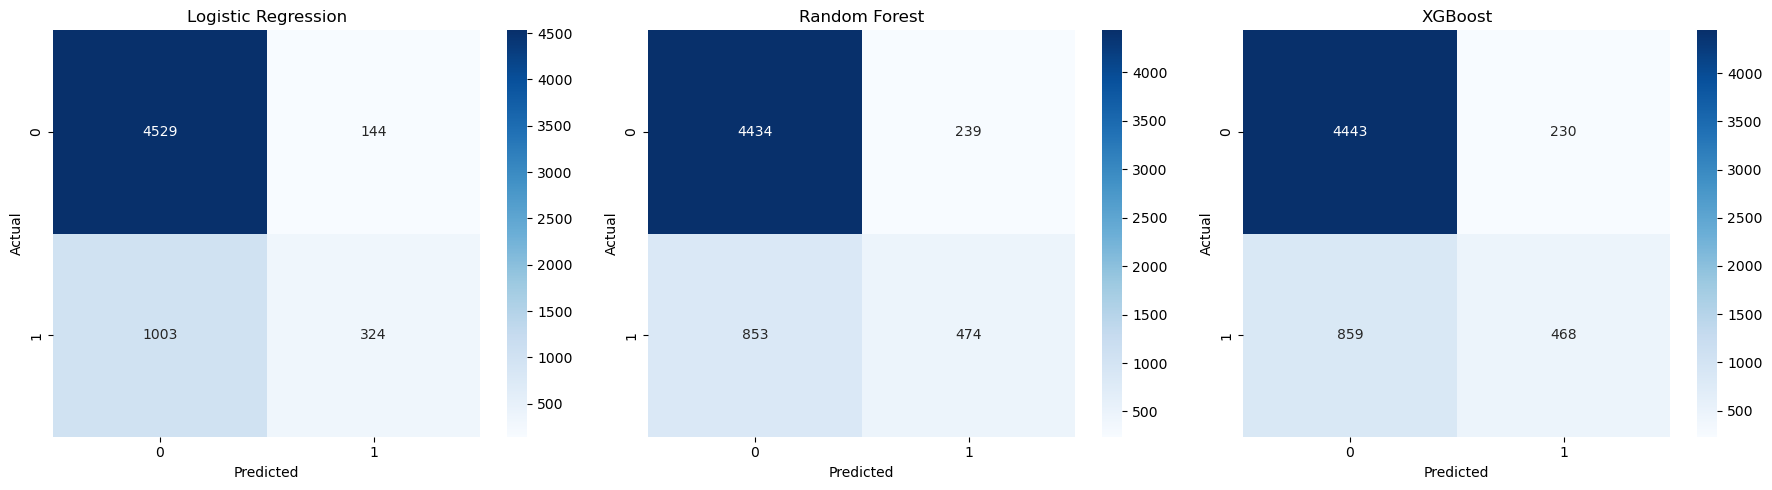

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_predictions = [
    ("Logistic Regression", lr_pred),
    ("Random Forest", rf_pred),
    ("XGBoost", xgb_pred)
]

for ax, (model_name, predictions) in zip(axes, model_predictions):
    sns.heatmap(
        confusion_matrix(y_test, predictions),
        annot=True, fmt="d", cmap="Blues", ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 16. ROC Curve

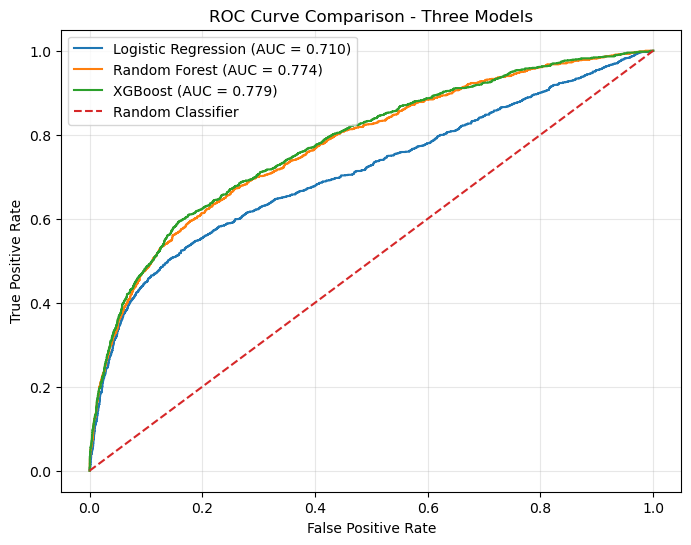

In [31]:
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    lr_fpr, lr_tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, lr_prob):.3f})"
)
plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_prob):.3f})"
)
plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {roc_auc_score(y_test, xgb_prob):.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Three Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 17. SMOTE vs Non-SMOTE Comparison

In [32]:
xgb_smote = XGBClassifier(
    **xgb_search.best_params_,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_smote.fit(X_train_smote, y_train_smote)

smote_prob = xgb_smote.predict_proba(X_test_processed)[:, 1]
smote_pred = (smote_prob >= 0.50).astype(int)

smote_comparison = pd.DataFrame([
    evaluate_model(
        "XGBoost - Without SMOTE",
        y_test, (xgb_prob >= 0.50).astype(int), xgb_prob
    ),
    evaluate_model(
        "XGBoost - With SMOTE",
        y_test, smote_pred, smote_prob
    )
])

display(
    smote_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost - Without SMOTE,81.93%,67.04%,36.02%,46.86%,77.93%
1,XGBoost - With SMOTE,79.42%,53.61%,51.47%,52.52%,76.82%


## 18. SHAP Explainability

In [33]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_processed_df)

if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

print("SHAP shape:", shap_values.shape)

SHAP shape: (6000, 38)


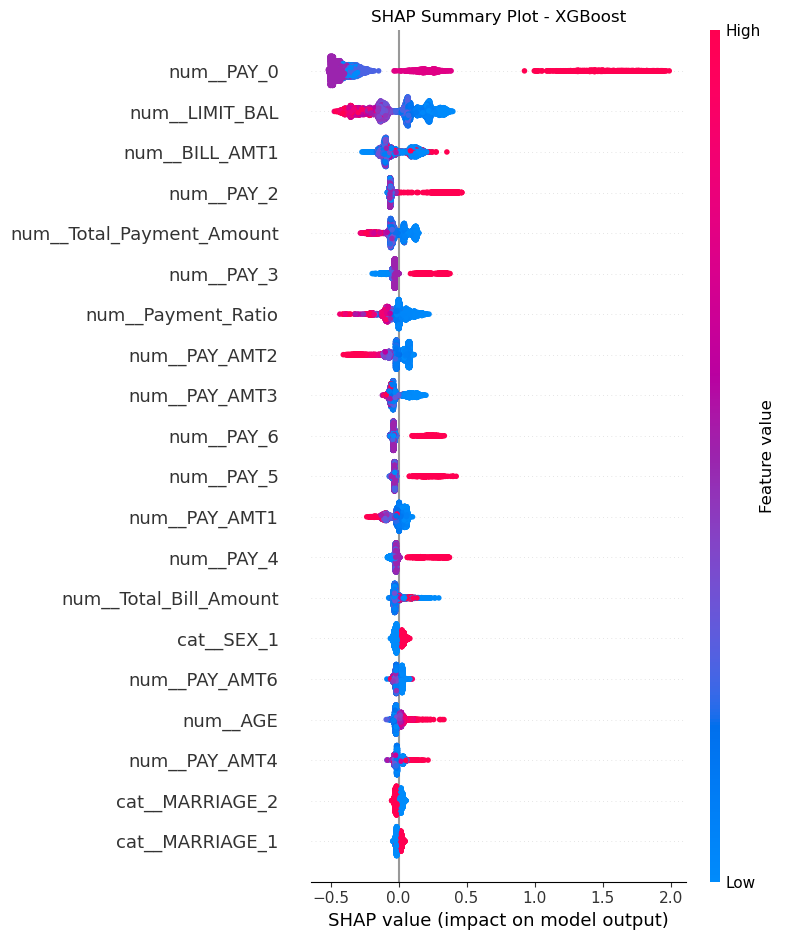

In [34]:
plt.figure()
shap.summary_plot(
    shap_values,
    X_test_processed_df,
    feature_names=feature_names,
    show=False
)
plt.title("SHAP Summary Plot - XGBoost")
plt.tight_layout()
plt.show()

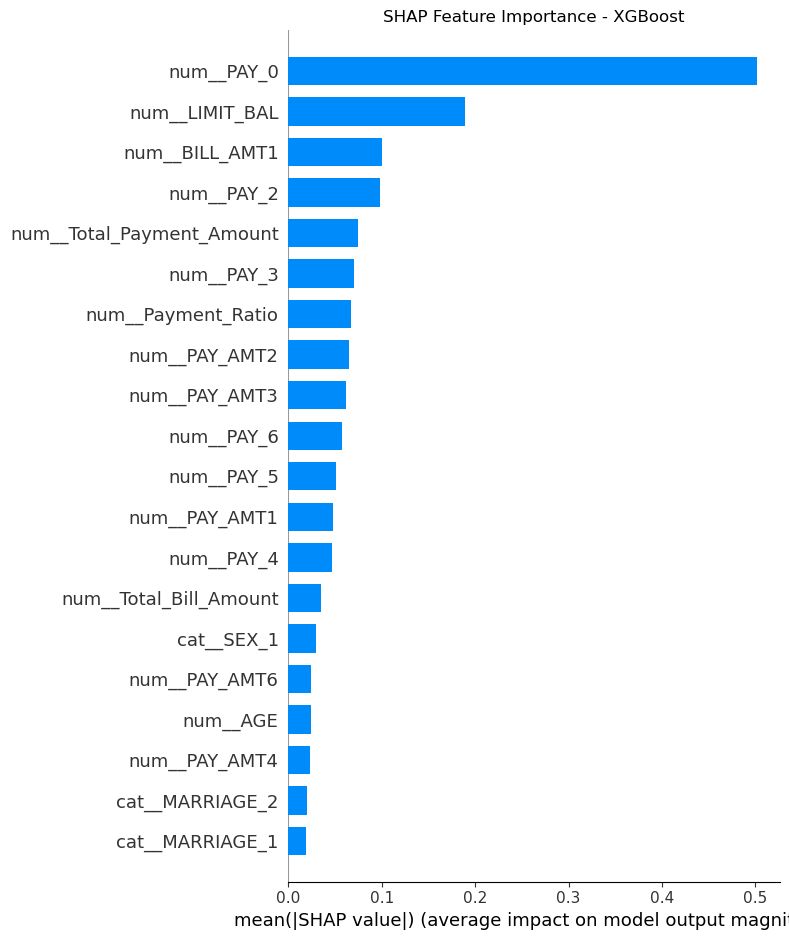

In [35]:
plt.figure()
shap.summary_plot(
    shap_values,
    X_test_processed_df,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)
plt.title("SHAP Feature Importance - XGBoost")
plt.tight_layout()
plt.show()

In [36]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values("Mean_SHAP", ascending=False)

display(feature_importance.head(15))

,Feature,Mean_SHAP
2,num__PAY_0,0.501309
0,num__LIMIT_BAL,0.188639
8,num__BILL_AMT1,0.099707
3,num__PAY_2,0.098346
21,num__Total_Payment_Amount,0.074079
4,num__PAY_3,0.070169
24,num__Payment_Ratio,0.066952
15,num__PAY_AMT2,0.064424
16,num__PAY_AMT3,0.061719
7,num__PAY_6,0.056937


## 19. Individual Customer SHAP Explanation

In [37]:
customer_index = 0
customer_probability = float(xgb_prob[customer_index])
customer_prediction = int(xgb_pred[customer_index])

print("Predicted Class:", customer_prediction)
print("Default Probability:",
      round(customer_probability * 100, 2), "%")

if customer_probability >= 0.70:
    print("Risk Level: High Risk")
elif customer_probability >= 0.40:
    print("Risk Level: Medium Risk")
else:
    print("Risk Level: Low Risk")

Predicted Class: 0
Default Probability: 13.41 %
Risk Level: Low Risk


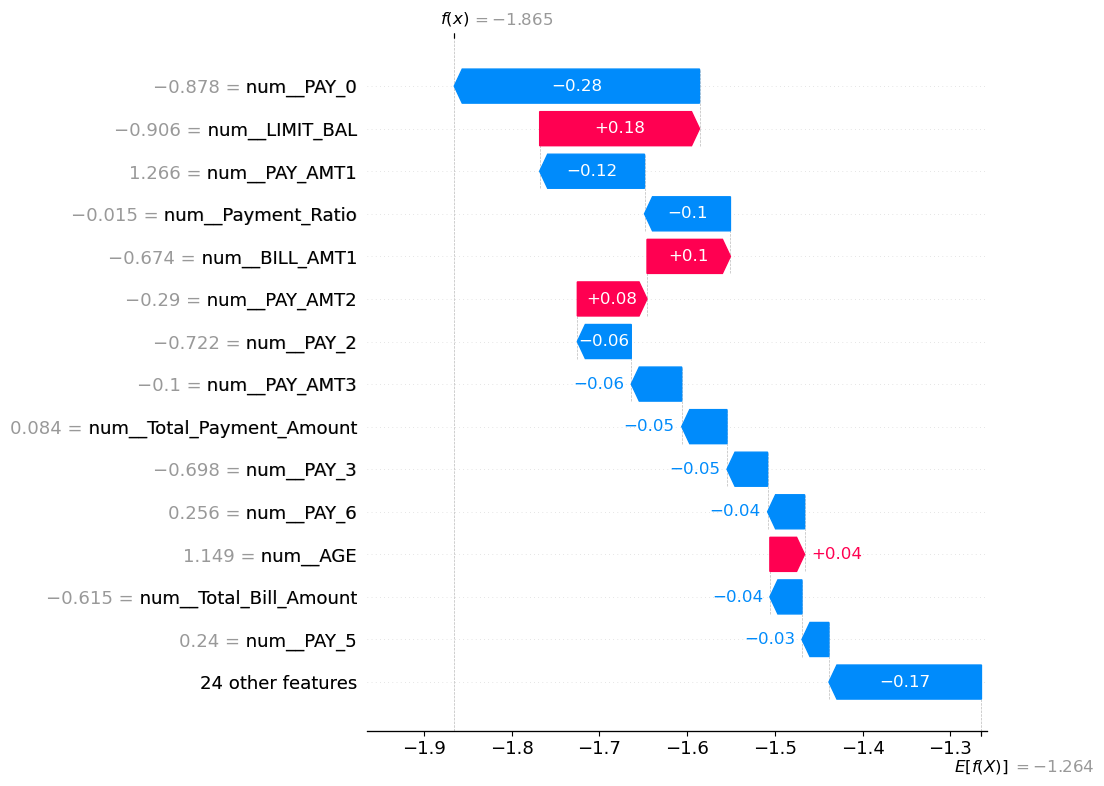

In [38]:
base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).reshape(-1)[-1]

customer_explanation = shap.Explanation(
    values=shap_values[customer_index],
    base_values=base_value,
    data=X_test_processed_df.iloc[customer_index].values,
    feature_names=feature_names
)

shap.plots.waterfall(customer_explanation, max_display=15)

In [39]:
customer_shap = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": shap_values[customer_index],
    "Feature_Value": X_test_processed_df.iloc[customer_index].values
})

customer_shap["Absolute_SHAP"] = customer_shap["SHAP_Value"].abs()
customer_shap = customer_shap.sort_values(
    "Absolute_SHAP", ascending=False
)

display(customer_shap.head(10))

,Feature,SHAP_Value,Feature_Value,Absolute_SHAP
2,num__PAY_0,-0.279631,-0.877791,0.279631
0,num__LIMIT_BAL,0.182246,-0.906231,0.182246
14,num__PAY_AMT1,-0.119520,1.265573,0.119520
24,num__Payment_Ratio,-0.097969,-0.015216,0.097969
8,num__BILL_AMT1,0.095092,-0.674215,0.095092
15,num__PAY_AMT2,0.079457,-0.290332,0.079457
3,num__PAY_2,-0.061507,-0.722324,0.061507
16,num__PAY_AMT3,-0.057519,-0.099569,0.057519
21,num__Total_Payment_Amount,-0.051612,0.083711,0.051612
4,num__PAY_3,-0.046279,-0.697642,0.046279


## 20. Decision Support

In [40]:
def generate_decision_support(probability, shap_data):
    if probability >= 0.70:
        risk = "High Risk"
        message = (
            "The customer shows a high probability of credit default. "
            "Careful review of repayment behaviour and outstanding balances "
            "is recommended."
        )
    elif probability >= 0.40:
        risk = "Medium Risk"
        message = (
            "The customer shows a moderate probability of credit default. "
            "Monitoring repayment behaviour and payment patterns is recommended."
        )
    else:
        risk = "Low Risk"
        message = (
            "The customer shows a relatively low probability of credit default. "
            "Current repayment behaviour appears comparatively stable."
        )

    return {
        "Risk Level": risk,
        "Default Probability": round(probability * 100, 2),
        "Risk Increasing Factors": shap_data[
            shap_data["SHAP_Value"] > 0
        ].head(3)["Feature"].tolist(),
        "Risk Reducing Factors": shap_data[
            shap_data["SHAP_Value"] < 0
        ].head(3)["Feature"].tolist(),
        "Decision Support": message
    }

decision = generate_decision_support(
    customer_probability, customer_shap
)
decision

{'Risk Level': 'Low Risk',
 'Default Probability': 13.41,
 'Risk Increasing Factors': ['num__LIMIT_BAL',
  'num__BILL_AMT1',
  'num__PAY_AMT2'],
 'Risk Reducing Factors': ['num__PAY_0',
  'num__PAY_AMT1',
  'num__Payment_Ratio'],
 'Decision Support': 'The customer shows a relatively low probability of credit default. Current repayment behaviour appears comparatively stable.'}

## 21. Save Models, Preprocessor and Metadata

In [41]:
joblib.dump(logistic_model, "logistic_regression_model.pkl")
joblib.dump(random_forest_model, "random_forest_model.pkl")
joblib.dump(xgb_model, "xgboost_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(feature_names, "feature_names.pkl")
joblib.dump(numerical_features, "numerical_features.pkl")
joblib.dump(categorical_features, "categorical_features.pkl")
joblib.dump(best_threshold, "xgboost_threshold.pkl")
joblib.dump(engineered_features, "engineered_features.pkl")

results_df.to_csv("model_results.csv", index=False)

print("All final model files saved successfully, including Random Forest.")
print("XGBoost threshold:", best_threshold)

All final model files saved successfully, including Random Forest.
XGBoost threshold: 0.51


## 22. Dashboard-Safe Feature Engineering
The Streamlit app must recreate these five engineered features before calling the saved preprocessor. This prevents missing-column errors.

In [42]:
def add_engineered_features(customer_df):
    customer_df = customer_df.copy()

    customer_df["Total_Bill_Amount"] = customer_df[bill_columns].sum(axis=1)
    customer_df["Total_Payment_Amount"] = customer_df[payment_columns].sum(axis=1)
    customer_df["Average_Bill_Amount"] = customer_df[bill_columns].mean(axis=1)
    customer_df["Average_Payment_Amount"] = customer_df[payment_columns].mean(axis=1)
    customer_df["Payment_Ratio"] = (
        customer_df["Total_Payment_Amount"] /
        (customer_df["Total_Bill_Amount"].abs() + 1)
    )

    return customer_df


def predict_credit_risk(customer_data):
    customer_df = add_engineered_features(
        pd.DataFrame([customer_data])
    )

    processed = preprocessor.transform(customer_df)

    probability = float(
        xgb_model.predict_proba(processed)[0, 1]
    )

    prediction = int(probability >= best_threshold)

    if probability >= 0.70:
        risk = "High Risk"
    elif probability >= 0.40:
        risk = "Medium Risk"
    else:
        risk = "Low Risk"

    return {
        "Prediction": prediction,
        "Default Probability": round(probability * 100, 2),
        "Risk Level": risk
    }

In [43]:
# Test the dashboard prediction function
sample_customer = X_test.iloc[0].to_dict()
predict_credit_risk(sample_customer)

{'Prediction': 0, 'Default Probability': 13.41, 'Risk Level': 'Low Risk'}

## 23. Final Notes

**Do not manually edit the reported test accuracy.** If it is below 90%, report the actual result. A 90% value should only be claimed if the unseen test set actually produces it.

The project pipeline is:

**Financial Data → Preprocessing → Feature Engineering → XGBoost/Logistic Regression → Evaluation → SHAP → Decision Support → Streamlit Dashboard**